# 04 · Rebalancing recommendations and impact estimate

This turns the forecasts into the decision the operations manager actually makes: **which stations get a van, and when?**

* **Net drain** = forecast departures − expected arrivals over a time window. Positive means the dock loses bikes.
* **Drain ratio** = net drain ÷ dock capacity. A ratio of 1.0 means the window would empty a completely full dock.

Departures come from the LightGBM forecast (notebook 03). Arrivals are not modelled. They use each station's typical profile over the last 8 weeks of training data, by weekday/weekend and hour.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from plotting import set_style, save, SERIES, INK, INK_2, NEUTRAL, BLUE_RAMP
set_style()
import features, models as M
import rebalancing as R
preds = pd.read_parquet('../data/processed/test_predictions.parquet')
df = pd.read_parquet('../data/processed/features.parquet')
train, _ = M.split(df)
arr_exp = R.expected_arrivals(train)
types = pd.read_csv('../data/processed/station_types.csv', dtype={'station_id': str})[['station_id', 'station_type']]
print(preds.shape, preds['date'].min().date(), '->', preds['date'].max().date())

(58560, 19) 2026-04-01 -> 2026-05-31


## 1. Where and when stations are most at risk of running empty

In [2]:
risk = R.risk_table(preds, arr_exp, 'lightgbm').merge(types, on='station_id', how='left')
cols = ['display_name', 'station_type', 'day_type', 'window', 'nb_docks', 'forecast_departures', 'expected_arrivals', 'net_drain', 'drain_ratio', 'risk_empty']
top_empty = risk.head(15)[cols]
top_empty.style.format({'forecast_departures': '{:.0f}', 'expected_arrivals': '{:.0f}', 'net_drain': '{:+.0f}', 'drain_ratio': '{:.2f}'}).hide(axis='index')

display_name,station_type,day_type,window,nb_docks,forecast_departures,expected_arrivals,net_drain,drain_ratio,risk_empty
"Waterloo Station 3, Waterloo",Morning origin,Weekday,AM peak (07-09),35,166,3,+163,4.67,Very high
"Queen Street 1, Bank",Office / City,Weekday,PM peak (16-18),22,56,18,+38,1.73,Very high
"Waterloo Station 1, Waterloo",Morning origin,Weekday,AM peak (07-09),36,77,18,+59,1.65,Very high
"Serpentine Car Park, Hyde Park",Leisure / park,Weekend,Midday (10-15),18,60,31,+29,1.62,Very high
"Hyde Park Corner, Hyde Park",Leisure / park,Weekend,Midday (10-15),36,118,63,+54,1.51,Very high
"Queen Street 2, Bank",Office / City,Weekday,PM peak (16-18),36,46,8,+39,1.07,Very high
"Serpentine Car Park, Hyde Park",Leisure / park,Weekend,PM peak (16-18),18,29,10,+18,1.02,Very high
"Hyde Park Corner, Hyde Park",Leisure / park,Weekday,Midday (10-15),36,72,39,+33,0.93,High
"Hyde Park Corner, Hyde Park",Leisure / park,Weekend,PM peak (16-18),36,65,33,+32,0.88,High
"St. James's Square, St. James's",Office / City,Weekday,PM peak (16-18),40,47,12,+34,0.86,High


**And the opposite problem: docks at risk of filling up (riders can't end a trip)**

In [3]:
top_full = risk.sort_values('drain_ratio').head(10)[cols[:-1] + ['risk_full']]
top_full.style.format({'forecast_departures': '{:.0f}', 'expected_arrivals': '{:.0f}', 'net_drain': '{:+.0f}', 'drain_ratio': '{:.2f}'}).hide(axis='index')

display_name,station_type,day_type,window,nb_docks,forecast_departures,expected_arrivals,net_drain,drain_ratio,risk_full
"Waterloo Station 3, Waterloo",Morning origin,Weekday,PM peak (16-18),35,8,168,-160,-4.57,Very high
"Queen Street 1, Bank",Office / City,Weekday,AM peak (07-09),22,10,94,-84,-3.83,Very high
"St. James's Square, St. James's",Office / City,Weekday,AM peak (07-09),40,6,74,-67,-1.69,Very high
"Queen Street 2, Bank",Office / City,Weekday,AM peak (07-09),36,9,68,-59,-1.65,Very high
"Imperial College, Knightsbridge",Office / City,Weekday,AM peak (07-09),33,6,53,-47,-1.43,Very high
"Brushfield Street, Liverpool Street",Office / City,Weekday,AM peak (07-09),34,10,56,-46,-1.36,Very high
"Exhibition Road, Knightsbridge",Mixed,Weekday,AM peak (07-09),20,9,35,-26,-1.29,Very high
"Waterloo Station 1, Waterloo",Morning origin,Weekday,PM peak (16-18),36,18,59,-41,-1.13,Very high
"Finsbury Circus, Liverpool Street",Office / City,Weekday,AM peak (07-09),33,19,55,-36,-1.10,Very high
"Moorfields, Moorgate",Office / City,Weekday,AM peak (07-09),54,11,70,-59,-1.09,Very high


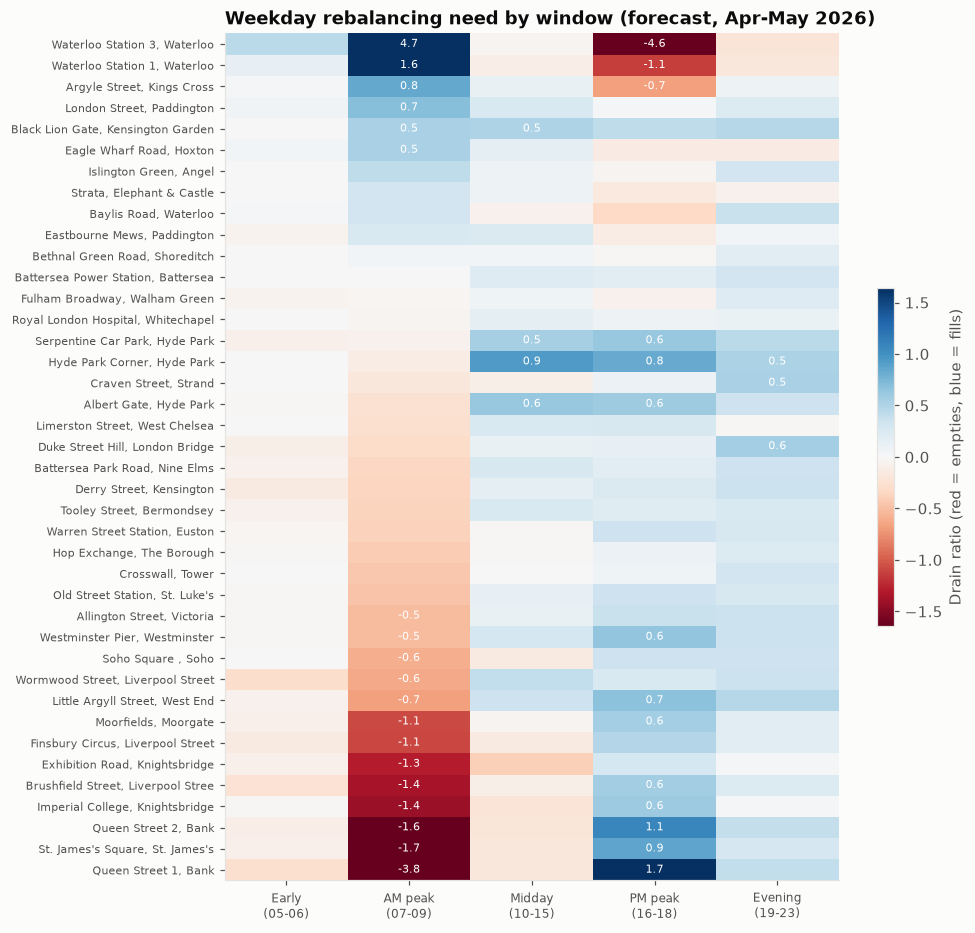

In [4]:
wk = risk[risk['day_type'] == 'Weekday'].pivot_table(index='display_name', columns='window', values='drain_ratio')
wk = wk[list(R.WINDOWS)].sort_values('AM peak (07-09)', ascending=False)
fig, ax = plt.subplots(figsize=(9, 10))
lim = np.nanpercentile(np.abs(wk.values), 97)
im = ax.imshow(wk.values, cmap='RdBu', vmin=-lim, vmax=lim, aspect='auto')
ax.set_yticks(range(len(wk)), [n[:34] for n in wk.index], fontsize=7.5)
ax.set_xticks(range(len(wk.columns)), [c.replace(' (', '\n(') for c in wk.columns], fontsize=8); ax.grid(False)
for i in range(len(wk)):
    for j in range(len(wk.columns)):
        v = wk.values[i, j]
        if abs(v) >= 0.5: ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=7, color='white')
cb = fig.colorbar(im, ax=ax, shrink=0.4); cb.set_label('Drain ratio (red = empties, blue = fills)')
ax.set_title('Weekday rebalancing need by window (forecast, Apr-May 2026)')
save(fig, '04_drain_ratio_heatmap');

## 2. The recommendation table

For each station and window: the forecast, the risk level, and a plain-English action. Thresholds:
* drain ratio > 1.0: *very high*. The dock empties even if it starts full, so it needs a top-up **during** the window as well as before it.
* 0.5 to 1.0: *high*. Fill to ≥ 90% **before** the window starts.
* below −0.5: *fill risk*. Take bikes **away** before the window (they can supply the draining docks).

In [5]:
def action(r):
    start = R.WINDOWS[r['window']][0]
    if r['drain_ratio'] > 1.0:  return f"Fill to 90%+ by {start-1:02d}:30 and send a second top-up mid-window"
    if r['drain_ratio'] > 0.5:  return f"Fill to 90%+ by {start-1:02d}:30"
    if r['drain_ratio'] < -1.0: return f"Clear to at most 20% full by {start-1:02d}:30 and again mid-window"
    if r['drain_ratio'] < -0.5: return f"Clear to at most 30% full by {start-1:02d}:30"
    return 'No action'
risk['bikes_to_move'] = (risk['net_drain'].abs()).round().astype(int)
risk['recommended_action'] = risk.apply(action, axis=1)
reco = risk[risk['recommended_action'] != 'No action'].copy()
reco['priority'] = reco['drain_ratio'].abs().rank(ascending=False, method='first').astype(int)
reco = reco.sort_values('priority')
print(f"{len(reco)} station-window actions ({(reco['drain_ratio'] > 0).sum()} refills, {(reco['drain_ratio'] < 0).sum()} clearances)")
reco[['priority', 'display_name', 'day_type', 'window', 'nb_docks', 'net_drain', 'drain_ratio', 'recommended_action']].head(20).style.format(
    {'net_drain': '{:+.0f}', 'drain_ratio': '{:.2f}'}).hide(axis='index')

53 station-window actions (36 refills, 17 clearances)


priority,display_name,day_type,window,nb_docks,net_drain,drain_ratio,recommended_action
1,"Waterloo Station 3, Waterloo",Weekday,AM peak (07-09),35,+163,4.67,Fill to 90%+ by 06:30 and send a second top-up mid-window
2,"Waterloo Station 3, Waterloo",Weekday,PM peak (16-18),35,-160,-4.57,Clear to at most 20% full by 15:30 and again mid-window
3,"Queen Street 1, Bank",Weekday,AM peak (07-09),22,-84,-3.83,Clear to at most 20% full by 06:30 and again mid-window
4,"Queen Street 1, Bank",Weekday,PM peak (16-18),22,+38,1.73,Fill to 90%+ by 15:30 and send a second top-up mid-window
5,"St. James's Square, St. James's",Weekday,AM peak (07-09),40,-67,-1.69,Clear to at most 20% full by 06:30 and again mid-window
6,"Waterloo Station 1, Waterloo",Weekday,AM peak (07-09),36,+59,1.65,Fill to 90%+ by 06:30 and send a second top-up mid-window
7,"Queen Street 2, Bank",Weekday,AM peak (07-09),36,-59,-1.65,Clear to at most 20% full by 06:30 and again mid-window
8,"Serpentine Car Park, Hyde Park",Weekend,Midday (10-15),18,+29,1.62,Fill to 90%+ by 09:30 and send a second top-up mid-window
9,"Hyde Park Corner, Hyde Park",Weekend,Midday (10-15),36,+54,1.51,Fill to 90%+ by 09:30 and send a second top-up mid-window
10,"Imperial College, Knightsbridge",Weekday,AM peak (07-09),33,-47,-1.43,Clear to at most 20% full by 06:30 and again mid-window


## 3. Impact estimate: what is targeted rebalancing worth?

**This is an estimate under stated assumptions, not a measured result.** The open data has no history of dock occupancy, so we simulate it.

**Set-up (every non-holiday weekday in the Apr-May 2026 test period):**
1. The night before, rank stations by **forecast** AM-peak drain ratio and send the van to the **top 10**.
2. Simulate each dock hour by hour from 06:00 to 09:59 using the **actual** departures and arrivals that happened.
3. *No van:* every dock starts at 50% full. *With van:* the 10 chosen docks start at 90% full.
4. A departure is *unmet* when the dock has no bike that hour.

**Assumptions to state openly:**
* Starting fill of 50% (sensitivity below at 30% and 70%), and one van visit per station before 06:00.
* Riders who find an empty dock are counted as a lost trip (some would walk to a neighbouring dock).
* Arrivals within an hour are assumed to be available to re-hire in the same hour (optimistic, so unmet trips are a **lower bound**).
* Observed departures are themselves capped by bike availability (TfL already rebalances), so true demand at the busiest docks is probably higher.
* The comparison is *targeted van vs no van*, not *vs TfL's current operation*, which is not published.

We run the same exercise choosing stations with each model's forecast, so the gain from a **better forecast** shows up as trips served.

In [6]:
pa = preds.merge(arr_exp, on=['station_id', 'is_weekend', 'hour'], how='left')
selectors = {'Naive (last week)': 'naive', 'Poisson regression': 'poisson', 'Random forest': 'random_forest',
             'LightGBM': 'lightgbm', 'Perfect foresight (upper bound)': 'departures'}
rows = []
for fill in (0.3, 0.5, 0.7):
    for lab, col in selectors.items():
        sim = R.simulate_am_refill(pa, col, n_refill=10, start_fill=fill)
        rows.append({'start_fill': fill, 'selector': lab, 'weekdays': len(sim),
                     'unmet_no_van_per_week': sim['unmet_no_van'].mean() * 5,
                     'unmet_with_van_per_week': sim['unmet_with_van'].mean() * 5,
                     'trips_served_per_week': sim['trips_recovered'].mean() * 5})
impact = pd.DataFrame(rows)
impact.to_csv('../reports/impact_estimate.csv', index=False)
impact.pivot(index='selector', columns='start_fill', values='trips_served_per_week').loc[list(selectors)].round(0)

start_fill,0.3,0.5,0.7
selector,,,
Naive (last week),506.0,287.0,120.0
Poisson regression,528.0,297.0,123.0
Random forest,530.0,297.0,123.0
LightGBM,531.0,297.0,123.0
Perfect foresight (upper bound),528.0,297.0,123.0


In [7]:
central = impact[impact['start_fill'] == 0.5].set_index('selector').loc[list(selectors)]
lg, nv = central.loc['LightGBM'], central.loc['Naive (last week)']
lo, hi = impact[(impact['selector'] == 'LightGBM')]['trips_served_per_week'].agg(['min', 'max'])
print(f"No van: ~{lg['unmet_no_van_per_week']:,.0f} AM-peak departures/week would hit an empty dock (top-40 stations, 50% start).")
print(f"Pre-peak top-up of the 10 forecast-selected docks serves ~{lg['trips_served_per_week']:,.0f} of them per week "
      f"(range {lo:,.0f}-{hi:,.0f} for a 30-70% starting fill).")
print(f"Naive-selected: ~{nv['trips_served_per_week']:,.0f}/week; perfect foresight: ~{central.loc['Perfect foresight (upper bound)', 'trips_served_per_week']:,.0f}/week.")

No van: ~1,500 AM-peak departures/week would hit an empty dock (top-40 stations, 50% start).
Pre-peak top-up of the 10 forecast-selected docks serves ~297 of them per week (range 123-531 for a 30-70% starting fill).
Naive-selected: ~287/week; perfect foresight: ~297/week.


In [8]:
sim = R.simulate_am_refill(pa, 'lightgbm', n_refill=10, start_fill=0.5)
names = preds.drop_duplicates('station_id').set_index('station_id')['display_name']
picked = pd.Series([names[s] for c in sim['chosen'] for s in c]).value_counts()
print(f"Weekdays simulated: {len(sim)}")
picked.rename('weekdays selected').to_frame().head(14)

Weekdays simulated: 39


,weekdays selected
"Argyle Street, Kings Cross",39
"Waterloo Station 3, Waterloo",39
"Black Lion Gate, Kensington Gardens",39
"Waterloo Station 1, Waterloo",39
"Strata, Elephant & Castle",39
"Eagle Wharf Road, Hoxton",39
"Islington Green, Angel",39
"London Street, Paddington",39
"Baylis Road, Waterloo",38
"Eastbourne Mews, Paddington",31


**Finding: on weekday mornings, *which* docks need a van is structural.** The same 9-10 docks (Waterloo, King's Cross, Paddington, Hoxton, Angel, Elephant & Castle) are selected nearly every weekday by every model, even the naive one. The morning target list can be a fixed rota. The forecast adds value in two other places:

1. **Sizing.** How many bikes each dock needs varies with weather, season and holidays.
2. **Irregular days.** At weekends and on bank holidays, the at-risk docks change with the weather.

### 3a. Sizing: how many bikes to bring

In [9]:
q = preds[(preds['is_weekend'] == 0) & (preds['is_bank_holiday'] == 0) & preds['hour'].between(7, 9)]
w = q.groupby(['date', 'station_id'])[['departures', 'naive', 'poisson', 'random_forest', 'lightgbm']].sum()
top10 = w.groupby('station_id')['departures'].mean().nlargest(10).index
w = w[w.index.get_level_values(1).isin(top10)]
size = pd.DataFrame({LAB: {'mean_abs_error_bikes_per_station_day': (w[c] - w['departures']).abs().mean(),
                           'bikes_misjudged_per_morning_top10': (w[c] - w['departures']).abs().groupby(level=0).sum().mean(),
                           'bias_bikes_per_station_day': (w[c] - w['departures']).mean()}
                     for LAB, c in [('Naive (last week)', 'naive'), ('Poisson regression', 'poisson'),
                                    ('Random forest', 'random_forest'), ('LightGBM', 'lightgbm')]}).T
size.to_csv('../reports/sizing_error.csv')
d = size.loc['Naive (last week)', 'bikes_misjudged_per_morning_top10'] - size.loc['LightGBM', 'bikes_misjudged_per_morning_top10']
print(f"LightGBM misjudges AM-peak demand at the 10 busiest morning docks by {d:.0f} fewer bikes per weekday than naive "
      f"(~{d*5:.0f} per week): {1 - size.loc['LightGBM', 'mean_abs_error_bikes_per_station_day'] / size.loc['Naive (last week)', 'mean_abs_error_bikes_per_station_day']:.0%} less sizing error.")
size.round(1)

LightGBM misjudges AM-peak demand at the 10 busiest morning docks by 30 fewer bikes per weekday than naive (~148 per week): 23% less sizing error.


,mean_abs_error_bikes_per_station_day,bikes_misjudged_per_morning_top10,bias_bikes_per_station_day
Naive (last week),12.7,126.6,-3.6
Poisson regression,12.0,119.5,-4.1
Random forest,10.1,100.5,-4.9
LightGBM,9.7,97.1,-5.3


### 3b. Irregular days: weekend and bank-holiday top-ups at 10:00 (window 10:00-17:59)

In [10]:
wk_rows = []
for n in (3, 5, 10):
    for lab, col in selectors.items():
        s_ = R.simulate_refill(pa, col, n_refill=n, start_fill=0.5, hours=(10, 17), days='weekend')
        wk_rows.append({'vans': n, 'selector': lab, 'days': len(s_), 'trips_served_per_day': s_['trips_recovered'].mean()})
wk_imp = pd.DataFrame(wk_rows); wk_imp.to_csv('../reports/impact_weekend.csv', index=False)
wk_imp.pivot(index='selector', columns='vans', values='trips_served_per_day').loc[list(selectors)].round(1)

vans,3,5,10
selector,,,
Naive (last week),3.3,3.6,6.1
Poisson regression,4.4,4.5,6.2
Random forest,4.5,5.5,6.9
LightGBM,4.8,5.7,7.1
Perfect foresight (upper bound),5.6,5.9,8.6


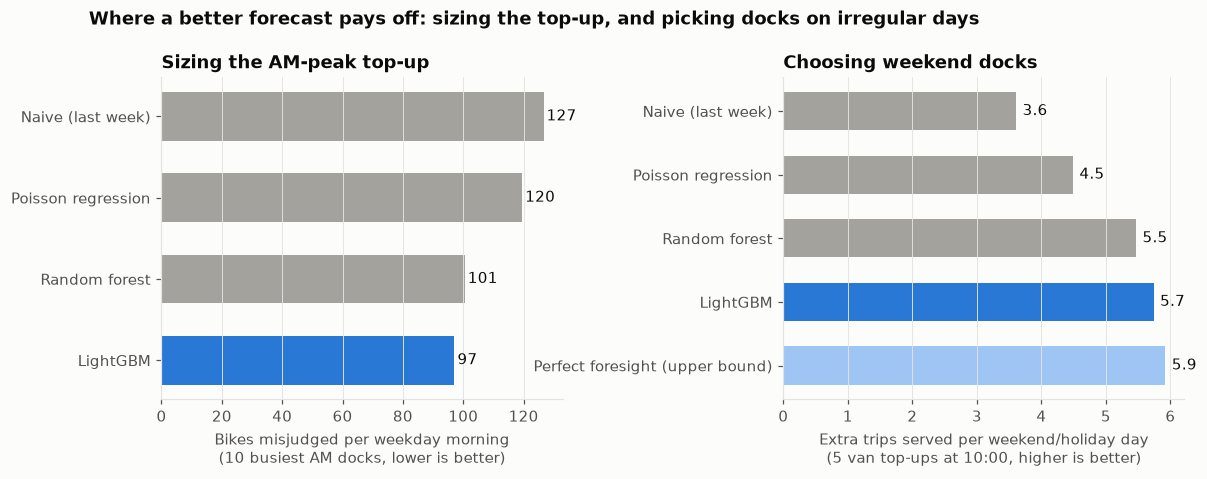

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
order = list(selectors)
cols_ = [NEUTRAL, NEUTRAL, NEUTRAL, SERIES[0], BLUE_RAMP[1]]
sz = size['bikes_misjudged_per_morning_top10'].reindex(order[:-1])
bars = axes[0].barh(sz.index[::-1], sz.values[::-1], color=cols_[:-1][::-1], height=0.6)
for b_ in bars: axes[0].text(b_.get_width() + 1, b_.get_y() + b_.get_height()/2, f'{b_.get_width():.0f}', va='center', color=INK)
axes[0].set_xlabel('Bikes misjudged per weekday morning\n(10 busiest AM docks, lower is better)'); axes[0].set_title('Sizing the AM-peak top-up')
v5 = wk_imp[wk_imp['vans'] == 5].set_index('selector').loc[order, 'trips_served_per_day']
bars = axes[1].barh(v5.index[::-1], v5.values[::-1], color=cols_[::-1], height=0.6)
for b_ in bars: axes[1].text(b_.get_width() + 0.1, b_.get_y() + b_.get_height()/2, f'{b_.get_width():.1f}', va='center', color=INK)
axes[1].set_xlabel('Extra trips served per weekend/holiday day\n(5 van top-ups at 10:00, higher is better)'); axes[1].set_title('Choosing weekend docks')
for ax in axes: ax.grid(axis='y', visible=False)
fig.suptitle('Where a better forecast pays off: sizing the top-up, and picking docks on irregular days', x=0.07, y=1.04, ha='left', fontweight='bold')
fig.subplots_adjust(wspace=0.55)
save(fig, '04_forecast_value');

## 4. Exports for the Power BI dashboard

In [12]:
import pathlib, sqlite3
out = pathlib.Path('../dashboard/data'); out.mkdir(parents=True, exist_ok=True)
st = pd.read_csv('../data/processed/station_types.csv', dtype={'station_id': str})
st.to_csv(out / 'dim_station.csv', index=False)

hist = df[['station_id', 'hour_ts', 'date', 'hour', 'dow', 'month', 'is_weekend', 'is_bank_holiday', 'is_school_holiday',
           'is_outage', 'temperature', 'precipitation', 'wind_speed', 'departures', 'arrivals']].copy()
hist.to_csv(out / 'fact_demand_hourly.csv', index=False)

fva = preds[['station_id', 'hour_ts', 'date', 'hour', 'is_weekend', 'is_bank_holiday', 'temperature', 'precipitation',
             'departures', 'naive', 'poisson', 'random_forest', 'lightgbm']].copy()
fva.to_csv(out / 'fact_forecast_vs_actual.csv', index=False)

reco_out = risk[['station_id', 'display_name', 'station_type', 'nb_docks', 'day_type', 'window', 'forecast_departures', 'actual_departures',
                 'expected_arrivals', 'net_drain', 'drain_ratio', 'risk_empty', 'risk_full', 'bikes_to_move', 'recommended_action']]
reco_out.to_csv(out / 'rebalancing_recommendations.csv', index=False)
pd.read_csv('../reports/model_metrics.csv').rename(columns={'Unnamed: 0': 'model'}).to_csv(out / 'model_metrics.csv', index=False)
impact.to_csv(out / 'impact_estimate.csv', index=False)
wk_imp.to_csv(out / 'impact_weekend.csv', index=False)
size.to_csv(out / 'sizing_error.csv')
for f in sorted(out.iterdir()): print(f'{f.name:34s} {sum(1 for _ in open(f)) - 1:>8,} rows')

dim_station.csv                          40 rows
fact_demand_hourly.csv              350,400 rows
fact_forecast_vs_actual.csv          58,560 rows
impact_estimate.csv                      15 rows
impact_weekend.csv                       15 rows
model_metrics.csv                         4 rows
rebalancing_recommendations.csv         400 rows
sizing_error.csv                          4 rows
